In [13]:
'''Perform nested cross-validation to assess model generalization capability and 
avoid data leakage, providing unbiased performance estimates 
for highly complex classification tasks.'''

'Perform nested cross-validation to assess model generalization capability and \navoid data leakage, providing unbiased performance estimates \nfor highly complex classification tasks.'

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)

# keep results repeatable
RANDOM_STATE = 42

In [15]:

data = load_breast_cancer(as_frame=True)
X = data.data.copy()
y = data.target.copy()

# show the dataset size and target balance
print("feature shape:", X.shape)
print("target shape:", y.shape)
print("target classes:", list(data.target_names))
display(X.head())

print("\nclass counts:")
print(y.value_counts().sort_index())

feature shape: (569, 30)
target shape: (569,)
target classes: [np.str_('malignant'), np.str_('benign')]


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [ ]:
print("missing values:", X.isnull().sum().sum())
print("duplicate feature rows:", X.duplicated().sum())

# show how many rows belong to each class
print("\nclass counts:")
for class_id, class_name in enumerate(data.target_names):
    print(class_name, ":", int((y == class_id).sum()))

missing values: 0
duplicate feature rows: 0

class counts:
malignant : 212
benign : 357


In [ ]:
# create model pipelines and parameter grids
logistic_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif)),
    ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])

forest_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("select", SelectKBest(score_func=f_classif)),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))
])

extra_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("select", SelectKBest(score_func=f_classif)),
    ("model", ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=1))
])

# test a manageable range of settings
model_grids = {
    "logistic regression": (logistic_pipe, {
        "select__k": [10, 20, "all"],
        "model__C": [0.1, 1, 10],
        "model__class_weight": [None, "balanced"]
    }),
    "random forest": (forest_pipe, {
        "select__k": [10, 20, "all"],
        "model__n_estimators": [150],
        "model__max_depth": [None, 8],
        "model__min_samples_leaf": [1, 3],
        "model__class_weight": [None, "balanced"]
    }),
    "extra trees": (extra_pipe, {
        "select__k": [10, 20, "all"],
        "model__n_estimators": [150],
        "model__max_depth": [None, 8],
        "model__min_samples_leaf": [1, 3],
        "model__class_weight": [None, "balanced"]
    })
}

print("models:", list(model_grids.keys()))


models: ['logistic regression', 'random forest', 'extra trees']


In [ ]:
#define the outer and inner folds
outer_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)
inner_cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=RANDOM_STATE + 1
)

print("outer folds:", outer_cv.get_n_splits())
print("inner folds:", inner_cv.get_n_splits())

outer folds: 5
inner folds: 3


In [ ]:
#run nested cross-validation
results = []
best_params_by_fold = []
confusion_matrices = {}

for fold_no, (train_idx, test_idx) in enumerate(outer_cv.split(X, y), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    print(f"outer fold {fold_no}/5")

    for model_name, (pipe, param_grid) in model_grids.items():
        # tune settings using only the outer training fold
        search = GridSearchCV(
            estimator=pipe,
            param_grid=param_grid,
            scoring="roc_auc",
            cv=inner_cv,
            n_jobs=-1,
            refit=True,
            error_score="raise"
        )
        search.fit(X_train, y_train)

        # evaluate the chosen pipeline on the outer test fold
        best_model = search.best_estimator_
        y_pred = best_model.predict(X_test)
        y_prob = best_model.predict_proba(X_test)[:, 1]

        results.append({
            "model": model_name,
            "outer_fold": fold_no,
            "accuracy": accuracy_score(y_test, y_pred),
            "precision": precision_score(y_test, y_pred, zero_division=0),
            "recall": recall_score(y_test, y_pred, zero_division=0),
            "f1": f1_score(y_test, y_pred, zero_division=0),
            "roc_auc": roc_auc_score(y_test, y_prob)
        })

        best_params_by_fold.append({
            "model": model_name,
            "outer_fold": fold_no,
            "inner_best_roc_auc": search.best_score_,
            "best_params": search.best_params_
        })
        confusion_matrices[(model_name, fold_no)] = confusion_matrix(y_test, y_pred)

        print(f"  {model_name}: outer roc auc = {roc_auc_score(y_test, y_prob):.3f}")

results_df = pd.DataFrame(results)
params_df = pd.DataFrame(best_params_by_fold)

print("\nnested cross-validation completed")
display(results_df.head())

outer fold 1/5
  logistic regression: outer roc auc = 0.997
  random forest: outer roc auc = 0.999
  extra trees: outer roc auc = 0.999
outer fold 2/5
  logistic regression: outer roc auc = 0.997
  random forest: outer roc auc = 0.978
  extra trees: outer roc auc = 0.990
outer fold 3/5
  logistic regression: outer roc auc = 0.985
  random forest: outer roc auc = 0.985
  extra trees: outer roc auc = 0.987
outer fold 4/5
  logistic regression: outer roc auc = 0.999
  random forest: outer roc auc = 0.996
  extra trees: outer roc auc = 0.995
outer fold 5/5
  logistic regression: outer roc auc = 0.999
  random forest: outer roc auc = 0.993
  extra trees: outer roc auc = 0.996

nested cross-validation completed


,model,outer_fold,accuracy,precision,recall,f1,roc_auc
0,logistic regression,1,0.956140,0.971429,0.957746,0.964539,0.997052
1,random forest,1,0.973684,0.985714,0.971831,0.978723,0.999017
2,extra trees,1,0.982456,1.000000,0.971831,0.985714,0.999345
3,logistic regression,2,0.947368,0.922078,1.000000,0.959459,0.997052
4,random forest,2,0.956140,0.945946,0.985915,0.965517,0.977891


In [ ]:
#summarize outer-fold performance
metric_cols = ["accuracy", "precision", "recall", "f1", "roc_auc"]

# report the average score and variation between outer folds
summary = results_df.groupby("model")[metric_cols].agg(["mean", "std"])
display(summary.round(4))

auc_summary = (
    results_df.groupby("model")["roc_auc"]
    .agg(mean_roc_auc="mean", std_roc_auc="std")
    .sort_values("mean_roc_auc", ascending=False)
)
display(auc_summary.round(4))

accuracy         precision          recall          \
                        mean     std      mean     std    mean     std   
model                                                                    
extra trees           0.9561  0.0214    0.9606  0.0402  0.9721  0.0326   
logistic regression   0.9667  0.0168    0.9654  0.0311  0.9832  0.0230   
random forest         0.9613  0.0100    0.9671  0.0177  0.9721  0.0240   

                         f1         roc_auc          
                       mean     std    mean     std  
model                                                
extra trees          0.9654  0.0166  0.9935  0.0048  
logistic regression  0.9737  0.0131  0.9954  0.0059  
random forest        0.9692  0.0082  0.9902  0.0087

,mean_roc_auc,std_roc_auc
model,,
logistic regression,0.9954,0.0059
extra trees,0.9935,0.0048
random forest,0.9902,0.0087


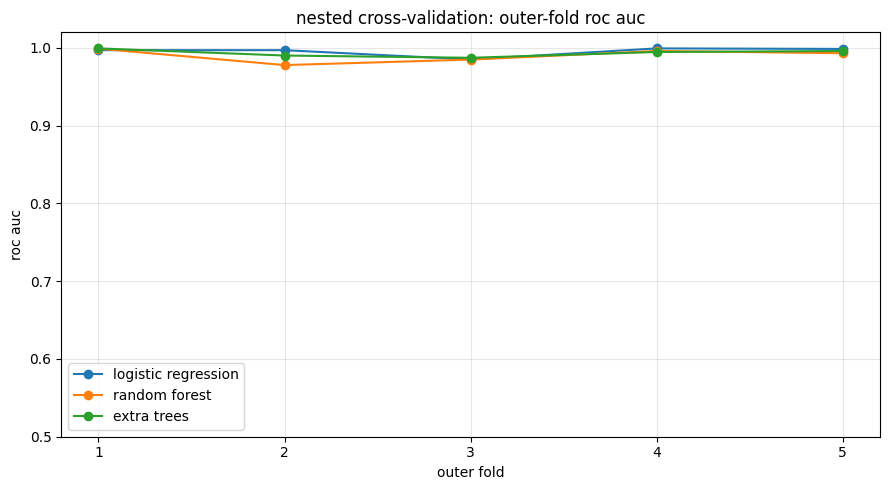

In [ ]:
plt.figure(figsize=(9, 5))

for model_name in results_df["model"].unique():
    rows = results_df[results_df["model"] == model_name]
    plt.plot(rows["outer_fold"], rows["roc_auc"], marker="o", label=model_name)

plt.xlabel("outer fold")
plt.ylabel("roc auc")
plt.title("nested cross-validation: outer-fold roc auc")
plt.xticks(sorted(results_df["outer_fold"].unique()))
plt.ylim(0.5, 1.02)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
display(params_df[["model", "outer_fold", "inner_best_roc_auc", "best_params"]])

,model,outer_fold,inner_best_roc_auc,best_params
0,logistic regression,1,0.996406,"{'model__C': 10, 'model__class_weight': None, ..."
1,random forest,1,0.992461,"{'model__class_weight': 'balanced', 'model__ma..."
2,extra trees,1,0.992525,"{'model__class_weight': 'balanced', 'model__ma..."
3,logistic regression,2,0.994546,"{'model__C': 0.1, 'model__class_weight': None,..."
4,random forest,2,0.992101,"{'model__class_weight': 'balanced', 'model__ma..."
5,extra trees,2,0.992940,"{'model__class_weight': None, 'model__max_dept..."
6,logistic regression,3,0.997969,"{'model__C': 1, 'model__class_weight': None, '..."
7,random forest,3,0.991309,"{'model__class_weight': None, 'model__max_dept..."
8,extra trees,3,0.995314,"{'model__class_weight': 'balanced', 'model__ma..."
9,logistic regression,4,0.994454,"{'model__C': 10, 'model__class_weight': 'balan..."


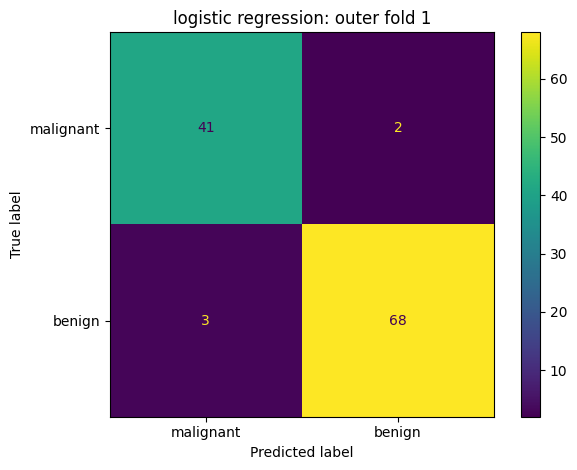

model shown: logistic regression


In [ ]:
#our fold confusion matrix 
best_model_name = auc_summary.index[0]
chosen_fold = 1
cm = confusion_matrices[(best_model_name, chosen_fold)]

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)
display.plot(values_format="d")
plt.title(f"{best_model_name}: outer fold {chosen_fold}")
plt.tight_layout()
plt.show()

print("model shown:", best_model_name)

In [ ]:
print("nested cross-validation summary")
for model_name, row in auc_summary.iterrows():
    print(
        f"{model_name}: mean roc auc = {row['mean_roc_auc']:.4f}, "
        f"std = {row['std_roc_auc']:.4f}"
    )



nested cross-validation summary
logistic regression: mean roc auc = 0.9954, std = 0.0059
extra trees: mean roc auc = 0.9935, std = 0.0048
random forest: mean roc auc = 0.9902, std = 0.0087
